In [1]:
source('../../../R/preamble.R')

In [2]:
library(lubridate)

In [3]:
d = read.tsv('../../../datasets/phage/phage_collapse/C_collapse_23_10_10.tsv') %>%
    mutate(time = ymd_hms(time)) %>% 
    arrange(time)

In [4]:
sub =
d %>%
    filter(
        Unit == 3,
        time > ymd_hm('23/10/09-23:30'),
        time < ymd_hm('23/10/10-12:20')
    )

Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


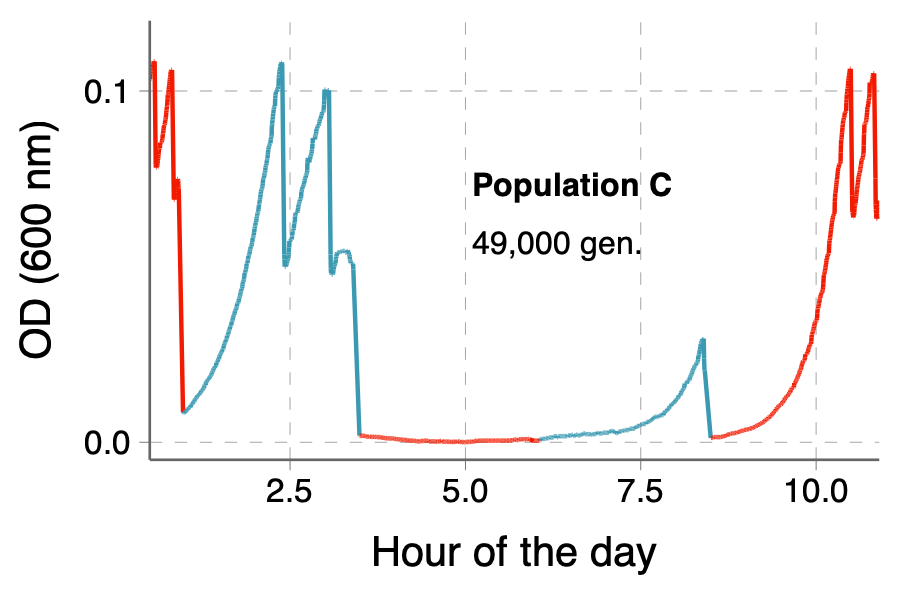

In [5]:
size(2, 3)

sub %>% 
    group_by(time) %>% arrange(OD) %>% filter(row_number() == 1) %>% # Only keep the growing pole (lowest OD)
    ungroup() %>% 
    
    arrange(time) %>% 
    filter(day(time) == 10) %>% 

    group_by(Pole) %>%
    mutate(
        OD2 = stats::runmed(OD, k = 9),
        # Calibration of OD-meter B was far off, giving negative OD values. Rescaling for display
        OD3 = ifelse(Pole == "B", (OD2 - min(OD2)) / (max(OD2) - min(OD2)) * (0.1 - min(OD2)), OD2),
        h = as.numeric(time - floor_date(time, 'day'), 'hours')
    ) %>% 
    filter(h > 0.5, h < 10.9) %>% 
    
ggplot() +
    aes(x = h, y = OD3, col = Pole, group = T) +
    nl +
    geom_line(lwd = 0.5) +

    xcont(0.5, 10.9) +
    ycont(-0.005, 0.12, breaks=c(0, 0.1)) +

    add_text(5.1, 0.07, 'Population C', fontface='bold', size=2.7, hjust=0, vjust=0) +
    add_text(5.1, 0.06, '49,000 gen.', fontface='plain', size=2.7, hjust=0, vjust=1) +

    labs(x = 'Hour of the day', y = 'OD (600 nm)')

psave('C_collapse_23_10_10')